# ML-1: Your first classifier

**Goal:** teach a computer to suggest a Barter Hub category from a listing's title and description.

In this notebook you will:

1. Look at a small labelled dataset.
2. Split it into examples to *learn from* and examples to *test on*.
3. Train a simple text classifier.
4. Measure how good it is, and see where it gets confused.

**A classifier** is a program that reads an input (here, text) and chooses one label from a fixed list (here, 16 categories). It learns by looking at many examples where the right answer is already known.

> The dataset in `../data/listings.csv` was written by hand for learning. It is not real user data. It has only 10 examples per category, so the numbers you see will be noisy. That is fine: the goal is to understand the process.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 1. Look at the data

Each row is one example listing with its correct category (the *label*).

In [11]:
data = pd.read_csv("../data/listings.csv")
data["text"] = data["title"] + ". " + data["description"]
print("Rows and columns:", data.shape)
data.head()

Rows and columns: (160, 5)


,title,description,category,kind,text
0,Data Structures and Algorithms textbook,Second edition with light notes in the margins.,books-and-study,item,Data Structures and Algorithms textbook. Secon...
1,Class 10 NCERT science books,"Full set, clean pages, good for board exam rev...",books-and-study,item,"Class 10 NCERT science books. Full set, clean ..."
2,Engineering mathematics notes,Handwritten notes for first year semester exams.,books-and-study,item,Engineering mathematics notes. Handwritten not...
3,Harry Potter paperback set,All seven books in good condition.,books-and-study,item,Harry Potter paperback set. All seven books in...
4,GATE preparation guide,"Previous year papers and solved examples, bare...",books-and-study,item,GATE preparation guide. Previous year papers a...


In [12]:
data["category"].value_counts()

category
books-and-study             10
electronics                 10
home-and-furniture          10
clothing-and-accessories    10
sports-and-outdoors         10
music-and-hobbies           10
kids-and-baby               10
other-things                10
tutoring-and-lessons        10
repairs-and-fixing          10
cooking-and-food            10
design-and-creative         10
tech-and-web                10
home-help                   10
care-and-wellness           10
other-services              10
Name: count, dtype: int64

## 2. Split the data

If we tested the model on the same examples it learned from, it could just memorise them and look perfect. So we hide some examples (the **test set**) and only use them at the end.

`stratify` keeps the same mix of categories in both parts. `random_state` makes the split repeatable.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    data["text"],
    data["category"],
    test_size=0.25,
    stratify=data["category"],
    random_state=42,
)
print(len(X_train), "examples to learn from,", len(X_test), "to test on")

120 examples to learn from, 40 to test on


## 3. Train a model

A computer cannot read words, so we turn text into numbers first:

- **TF-IDF** gives each word a score. Words that appear in few listings (like "guitar") get a higher score than words that appear everywhere (like "good").
- **Logistic regression** learns which words point towards which category.

A *pipeline* joins the two steps, so new text goes through both automatically.

In [14]:
model = make_pipeline(
    TfidfVectorizer(lowercase=True, ngram_range=(1, 2), stop_words="english"),
    LogisticRegression(max_iter=1000),
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Accuracy on the test set:", round(accuracy_score(y_test, predictions), 3))

Accuracy on the test set: 0.325


## 4. See how it did

**Accuracy** is the share of test listings that got the right category. The report below shows it per category:

- **precision**: when the model says "electronics", how often is it right?
- **recall**: of all real electronics listings, how many did it find?
- **support**: how many test examples that category had.

In [15]:
print(classification_report(y_test, predictions, zero_division=0))

                          precision    recall  f1-score   support

         books-and-study       1.00      0.50      0.67         2
       care-and-wellness       0.25      1.00      0.40         2
clothing-and-accessories       0.00      0.00      0.00         3
        cooking-and-food       0.00      0.00      0.00         3
     design-and-creative       0.50      0.33      0.40         3
             electronics       0.50      0.50      0.50         2
      home-and-furniture       0.00      0.00      0.00         3
               home-help       0.33      0.33      0.33         3
           kids-and-baby       0.25      0.50      0.33         2
       music-and-hobbies       0.20      0.50      0.29         2
          other-services       0.00      0.00      0.00         3
            other-things       0.00      0.00      0.00         2
      repairs-and-fixing       0.67      0.67      0.67         3
     sports-and-outdoors       0.20      0.50      0.29         2
         

A **confusion matrix** shows which categories get mixed up. Each row is the true category, each column is what the model guessed. A strong diagonal is good; numbers off the diagonal are mistakes.

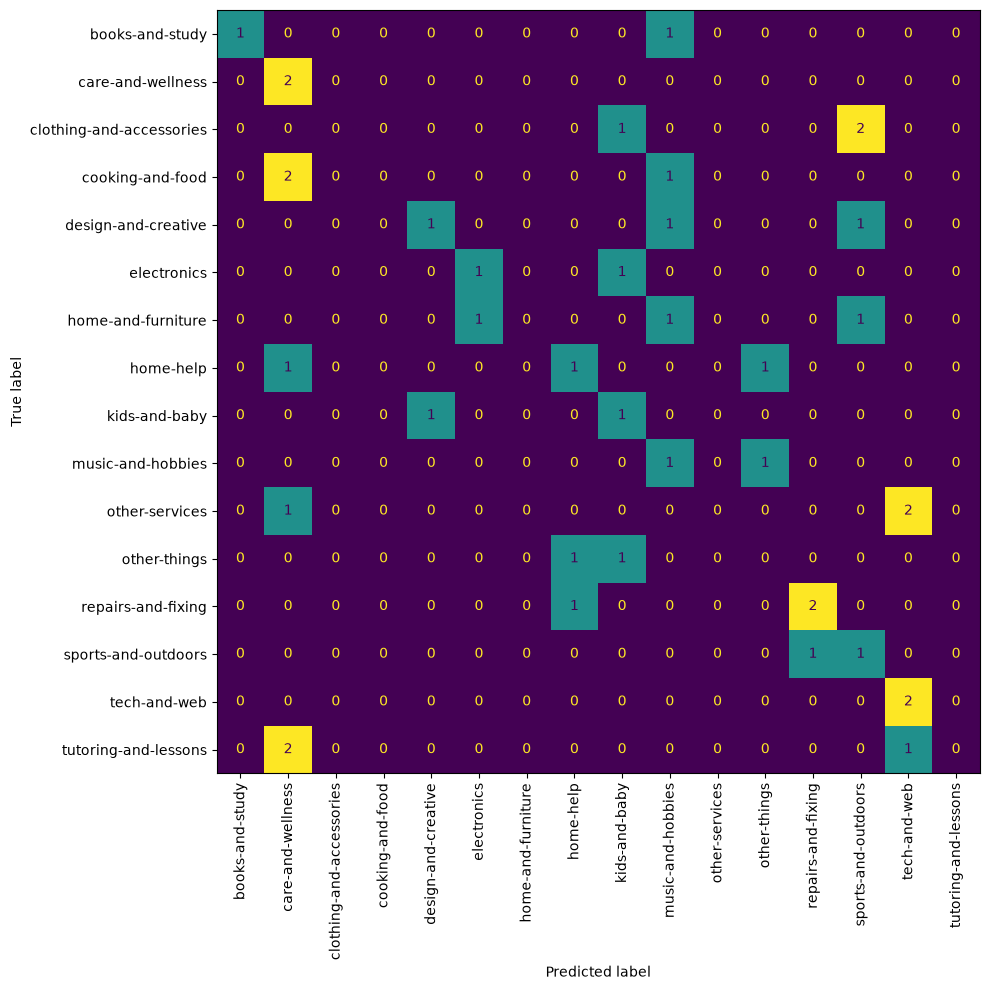

In [16]:
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, xticks_rotation=90, ax=ax, colorbar=False
)
plt.tight_layout()
plt.show()

## 5. A fairer score: cross-validation

With so few test examples, one lucky or unlucky split changes the score a lot. **Cross-validation** repeats the train and test process 5 times with different splits, and averages the result.

In [17]:
scores = cross_val_score(
    model,
    data["text"],
    data["category"],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
)
print("Accuracy in each of 5 rounds:", scores.round(3))
print("Average:", round(scores.mean(), 3))

Accuracy in each of 5 rounds: [0.312 0.375 0.281 0.25  0.281]
Average: 0.3


## 6. Try it yourself

The model can also say how *confident* it is. Type your own listing below.

In [18]:
def suggest(title, description="", top=3):
    text = f"{title}. {description}"
    probabilities = model.predict_proba([text])[0]
    ranked = sorted(zip(model.classes_, probabilities), key=lambda pair: pair[1], reverse=True)
    for category, probability in ranked[:top]:
        print(f"{category:28} {probability:.0%}")

suggest("Used tabla set", "Good sound, comes with a cushion")
print()
suggest("Maths homework help for class 9")

music-and-hobbies            11%
sports-and-outdoors          8%
electronics                  7%

tech-and-web                 8%
kids-and-baby                7%
other-services               7%


## Experiments

Change one thing at a time, run the cells again, and write down what happens.

1. **Which categories get confused most?** Look at the confusion matrix. Why might that be? (Hint: look at the two "other" categories.)
2. **Change `test_size`** to 0.2 and 0.4. How does the accuracy change? Why?
3. **Change `random_state`** to 1, 2, 3. Does the accuracy stay the same? What does that tell you about trusting one number?
4. **Use only the title.** Replace `data["text"]` with `data["title"]` in the split. Does the description help?
5. **Add five listings of your own** to `../data/listings.csv`, then run everything again.
6. **Break it on purpose.** Call `suggest()` with a title the model has never seen, in a category it knows well. How confident is it? What about nonsense like "asdf qwerty"?

## What you learned

- A classifier learns from labelled examples, and must be tested on examples it has not seen.
- One accuracy number from a small test set is unreliable, so we use cross-validation.
- The model's confidence matters. In the product, we will only show a suggestion when it is confident enough.

**Next (ML-2):** replace TF-IDF with a *pretrained sentence model*, which understands meaning and not only exact words.